In [5]:
# ============================================================
#  Disease Prediction ML Project
# Models: Logistic Regression + SVM
# Dataset: Heart Disease (Cleveland UCI)
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

In [15]:
# ──────────────────────────────────────────────
# 1. LOAD DATA (Mohamed Mazhar)



# load data from UCI
df = pd.read_csv("https://raw.githubusercontent.com/Kha1edAyman/Heart-Disease-Prediction-ML-Project/refs/heads/main/data/heart.csv?token=GHSAT0AAAAAADWAXRUHS4UBPGP2HLRUN63O2PZATLA")
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [16]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [17]:
# show info
print("Shape:", df.shape)
print(df.head())
df.info()
# ──────────────────────────────────────────────
# UCI Heart Disease Dataset columns

# mazhar Done ✅


Shape: (303, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  target  
0   0     1       1  
1   0     2       1  
2   0     2       1  
3   0     2       1  
4   0     2       1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-nu

=== 1. General Information About the Data (Info & Shape) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB
None

Shape: (303, 14)
--------------------------------------------------

=== 2. Descriptive Statistics (Describe) ===
              age         sex         

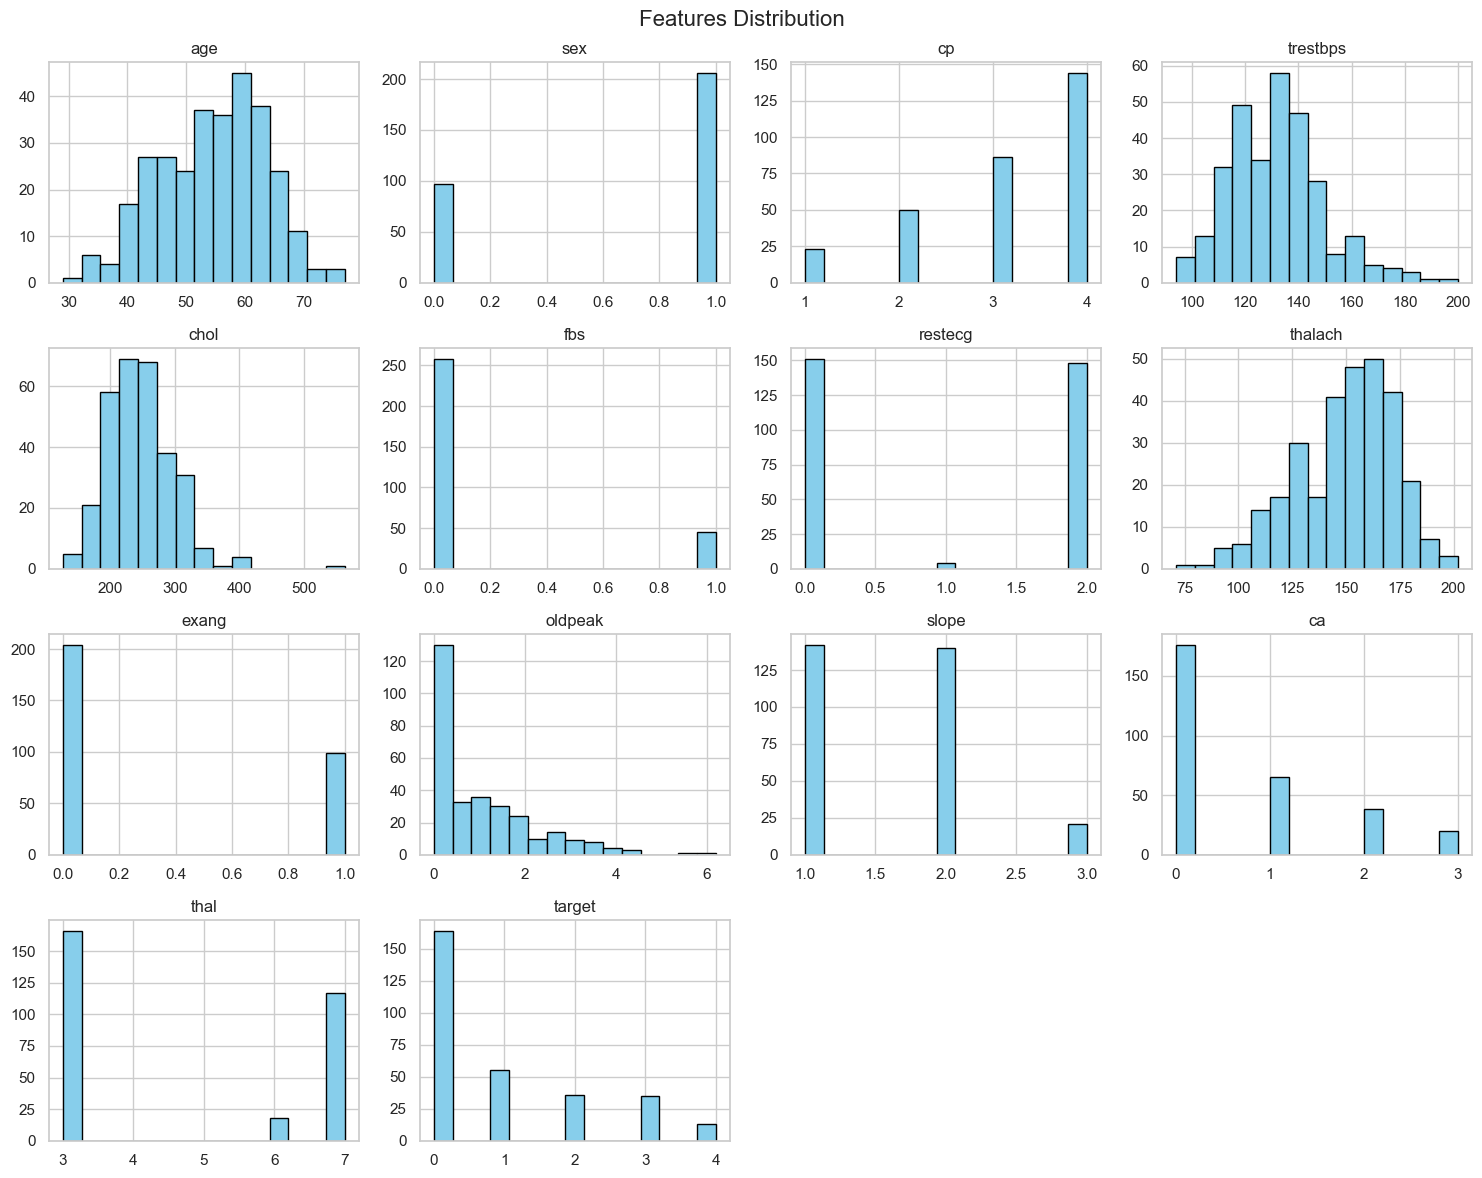


=== 5. Plotting Correlation Heatmap ===


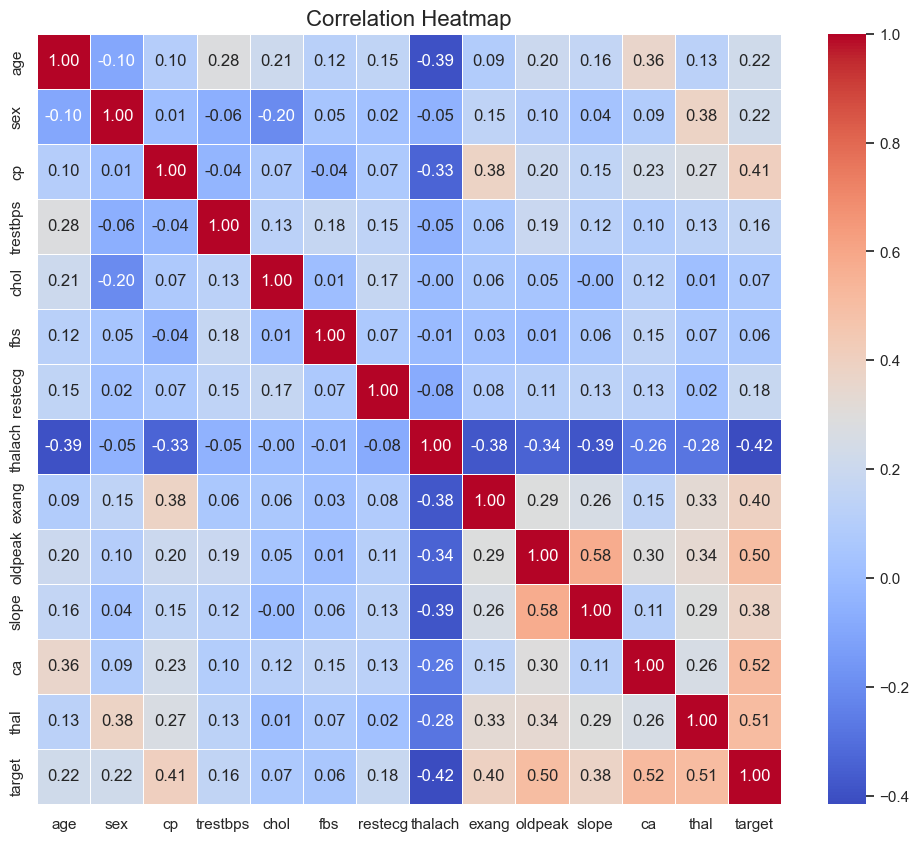


=== 6. Target Variable Distribution ===
Target Counts:
 target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


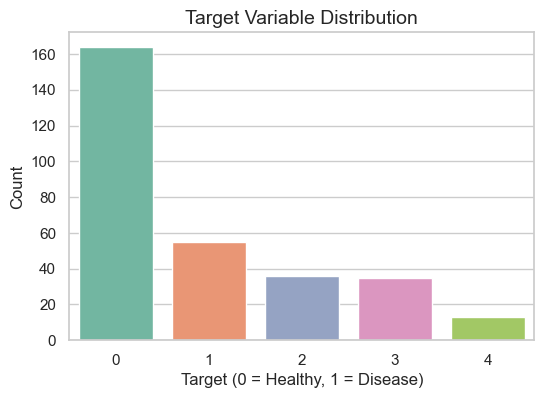

In [9]:
# ──────────────────────────────────────────────
# 2. EDA (yasmin)
# ──────────────────────────────────────────────

import matplotlib.pyplot as plt
import seaborn as sns

# Set Seaborn theme
sns.set_theme(style="whitegrid")

# 1. Print general information about the data
print("=== 1. General Information About the Data (Info & Shape) ===")
print(df.info())
print("\nShape:", df.shape)
print("-" * 50)

# 2. Print descriptive statistics
print("\n=== 2. Descriptive Statistics (Describe) ===")
print(df.describe())
print("-" * 50)

# 3. Check for missing values
print("\n=== 3. Missing values in each column ===")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])
print("-" * 50)

# 4. Plot the distribution for each column
print("\n=== 4. Plotting feature distributions (Histograms) ===")
df.hist(figsize=(15, 12), bins=15, color='skyblue', edgecolor='black')
plt.suptitle('Features Distribution', fontsize=16)
plt.tight_layout()
plt.show()

# 5. Plot the Correlation Heatmap
print("\n=== 5. Plotting Correlation Heatmap ===")
plt.figure(figsize=(12, 10))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=16)
plt.show()

# 6. Distribution of the target variable (healthy vs disease)
print("\n=== 6. Target Variable Distribution ===")
target_counts = df['target'].value_counts()
print("Target Counts:\n", target_counts)

plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, palette='Set2')
plt.title('Target Variable Distribution', fontsize=14)
plt.xlabel('Target (0 = Healthy, 1 = Disease)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()



In [10]:
# ──────────────────────────────────────────────
# 3. PREPROCESSING (fatma )
# ──────────────────────────────────────────────

df = df.dropna()
print("Shape after removing missing:", df.shape)

df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

print("\nTarget after conversion:")
print(df['target'].value_counts())

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("\nTrain size:", X_train.shape)
print("Test size:", X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # يتعلم من Train
X_test_scaled = scaler.transform(X_test) 

       # يطبق على Test
print("====== CHECK ======")
print("Shape:", df.shape)
print("Missing:\n", df.isnull().sum())
print("Target values:", df['target'].unique())
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Shape after removing missing: (297, 14)

Target after conversion:
target
0    160
1    137
Name: count, dtype: int64

Train size: (237, 13)
Test size: (60, 13)
====== CHECK ======
Shape: (297, 14)
Missing:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
Target values: [0 1]
Train shape: (237, 13)
Test shape: (60, 13)


In [11]:
# ──────────────────────────────────────────────
# 4. MODEL 1: LOGISTIC REGRESSION (Ahmed Amin)
# ──────────────────────────────────────────────



In [12]:
# ──────────────────────────────────────────────
# 5. MODEL 2: SVM (Khaled Ayman)
# ──────────────────────────────────────────────



In [13]:
# ──────────────────────────────────────────────
# 6. MODEL COMPARISON (Nada)
# ──────────────────────────────────────────────



In [14]:
# ──────────────────────────────────────────────
# 7. SAVE RESULTS (Khaled Ayman)
# ──────────────────────────────────────────────